# Analyze len500 dataset

Analysis of the **scored raw dataset** (generate → score, no preference pairs): basic stats and relation between the two scores (positiveness, length).

## 1. Basic stats, relation, and plots (all responses as a whole)

Load the scored raw dataset; stack all responses and show: stats of the two scores, their Pearson correlation, score distributions, and scatter (x=positiveness, y=length).

In [1]:
import numpy as np
import pandas as pd
from datasets import load_dataset
from scipy import stats

# Config: scored raw dataset (from build_dataset.sh with max_new_tokens=500)
USER_ID = "mxcui"
NUM_RESPONSES = 2
MAX_NEW_TOKENS = 512
EXP_TAG = f"n{NUM_RESPONSES}-len{MAX_NEW_TOKENS}-random"
RAW_DATASET_ID = f"{USER_ID}/gpt2-imdb-raw-{EXP_TAG}"

ds = load_dataset(RAW_DATASET_ID, split="train")
df = ds.to_pandas()

# Stack all response scores into single arrays (no grouping)
pos_cols = sorted([c for c in df.columns if c.startswith("positiveness_") and "_z_" not in c], key=lambda x: int(x.split("_")[1]))
len_cols = sorted([c for c in df.columns if c.startswith("length_")], key=lambda x: int(x.split("_")[1]))
pos_all = np.concatenate([df[c].values for c in pos_cols])
len_all = np.concatenate([df[c].values for c in len_cols])
n_scores = len(pos_all)
# Z-score columns (if present: positiveness_z_{i}, conciseness_z_{i})
pos_z_cols = sorted([c for c in df.columns if c.startswith("positiveness_z_")], key=lambda x: int(x.split("_")[-1]))
conc_z_cols = sorted([c for c in df.columns if c.startswith("conciseness_z_")], key=lambda x: int(x.split("_")[-1]))
has_z = len(pos_z_cols) == len(pos_cols) and len(conc_z_cols) == len(len_cols)
if has_z:
    pos_z_all = np.concatenate([df[c].values for c in pos_z_cols])
    conc_z_all = np.concatenate([df[c].values for c in conc_z_cols])
else:
    pos_z_all = conc_z_all = None

print("Dataset:", RAW_DATASET_ID)
print("Shape:", df.shape)
print("Total score values (all responses):", n_scores)
print()

Dataset: mxcui/gpt2-imdb-raw-n2-len512-random
Shape: (24895, 13)
Total score values (all responses): 49790



In [2]:
# Stats of the two scores (all responses as a whole)
print("=" * 60)
print("Stats (positiveness, length)")
print("=" * 60)
print("Positiveness:  count=%d  mean=%.4f  std=%.4f  min=%.4f  max=%.4f" % (n_scores, pos_all.mean(), pos_all.std(), pos_all.min(), pos_all.max()))
print("Length:        count=%d  mean=%.2f  std=%.2f  min=%d  max=%d" % (n_scores, len_all.mean(), len_all.std(), int(len_all.min()), int(len_all.max())))
print()
# Relation: Pearson
r, pval = stats.pearsonr(pos_all, len_all)
print("Pearson(positiveness, length):  r = %.4f,  p = %.4e" % (r, pval))
print()
if has_z:
    print("Stats (normalized: positiveness_z, conciseness_z)")
    print("=" * 60)
    print("Positiveness_z: count=%d  mean=%.4f  std=%.4f  min=%.4f  max=%.4f" % (n_scores, pos_z_all.mean(), pos_z_all.std(), pos_z_all.min(), pos_z_all.max()))
    print("Conciseness_z:  count=%d  mean=%.4f  std=%.4f  min=%.4f  max=%.4f" % (n_scores, conc_z_all.mean(), conc_z_all.std(), conc_z_all.min(), conc_z_all.max()))
    print()
    r_z, pval_z = stats.pearsonr(pos_z_all, conc_z_all)
    print("Pearson(positiveness_z, conciseness_z):  r = %.4f,  p = %.4e" % (r_z, pval_z))
    print()

Stats (positiveness, length)
Positiveness:  count=49790  mean=0.6230  std=0.4346  min=0.0027  max=0.9964
Length:        count=49790  mean=141.86  std=123.11  min=3  max=512

Pearson(positiveness, length):  r = -0.0382,  p = 1.5935e-17

Stats (normalized: positiveness_z, conciseness_z)
Positiveness_z: count=49790  mean=-0.0000  std=1.0000  min=-1.4270  max=0.8592
Conciseness_z:  count=49790  mean=-0.0000  std=1.0000  min=-3.0066  max=1.1280

Pearson(positiveness_z, conciseness_z):  r = 0.0382,  p = 1.5935e-17



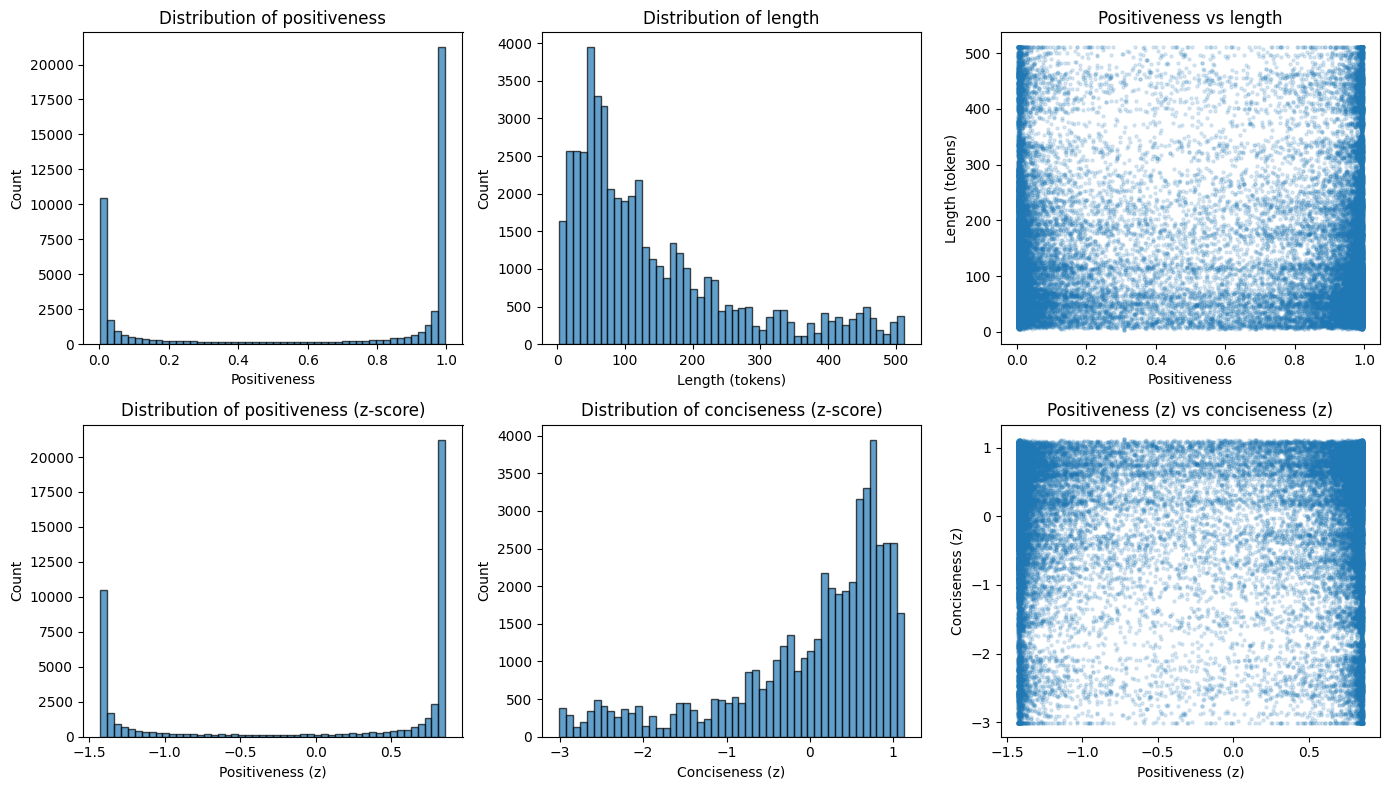

In [3]:
# Distribution of the two scores + scatter; add normalized (z) row if present
import matplotlib.pyplot as plt

n_rows = 2 if has_z else 1
fig, axes = plt.subplots(n_rows, 3, figsize=(14, 4 * n_rows))
if n_rows == 1:
    axes = axes.reshape(1, -1)
axes[0, 0].hist(pos_all, bins=50, edgecolor="black", alpha=0.7)
axes[0, 0].set_xlabel("Positiveness")
axes[0, 0].set_ylabel("Count")
axes[0, 0].set_title("Distribution of positiveness")
axes[0, 1].hist(len_all, bins=50, edgecolor="black", alpha=0.7)
axes[0, 1].set_xlabel("Length (tokens)")
axes[0, 1].set_ylabel("Count")
axes[0, 1].set_title("Distribution of length")
axes[0, 2].scatter(pos_all, len_all, alpha=0.15, s=5)
axes[0, 2].set_xlabel("Positiveness")
axes[0, 2].set_ylabel("Length (tokens)")
axes[0, 2].set_title("Positiveness vs length")
if has_z:
    axes[1, 0].hist(pos_z_all, bins=50, edgecolor="black", alpha=0.7)
    axes[1, 0].set_xlabel("Positiveness (z)")
    axes[1, 0].set_ylabel("Count")
    axes[1, 0].set_title("Distribution of positiveness (z-score)")
    axes[1, 1].hist(conc_z_all, bins=50, edgecolor="black", alpha=0.7)
    axes[1, 1].set_xlabel("Conciseness (z)")
    axes[1, 1].set_ylabel("Count")
    axes[1, 1].set_title("Distribution of conciseness (z-score)")
    axes[1, 2].scatter(pos_z_all, conc_z_all, alpha=0.15, s=5)
    axes[1, 2].set_xlabel("Positiveness (z)")
    axes[1, 2].set_ylabel("Conciseness (z)")
    axes[1, 2].set_title("Positiveness (z) vs conciseness (z)")
plt.tight_layout()
plt.show()

## 2. Distribution of score differences (chosen vs rejected)

Per-prompt difference from the **preference dataset**: **positiveness** (chosen − rejected) and **length** (chosen − rejected; length as proxy for conciseness). Scores are computed by scoring chosen/rejected with the gold (DistilBERT) scorer.

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Preference dataset: mxcui/gpt2-imdb-preference-ALPHA1.0-len512-random
Rows: 24720

Score differences (chosen − rejected)
  Positiveness:  mean= 0.3188  std=0.4594  min=-0.9927  max= 0.9930
  Length:        mean=-19.76  std=100.18  min=-246.0  max= 246.0
  Positiveness_z: mean=-0.0000  std=1.1290  min=-3.3572  max= 1.6297
  Conciseness_z:  mean= 0.0000  std=1.2438  min=-3.3053  max= 2.8084



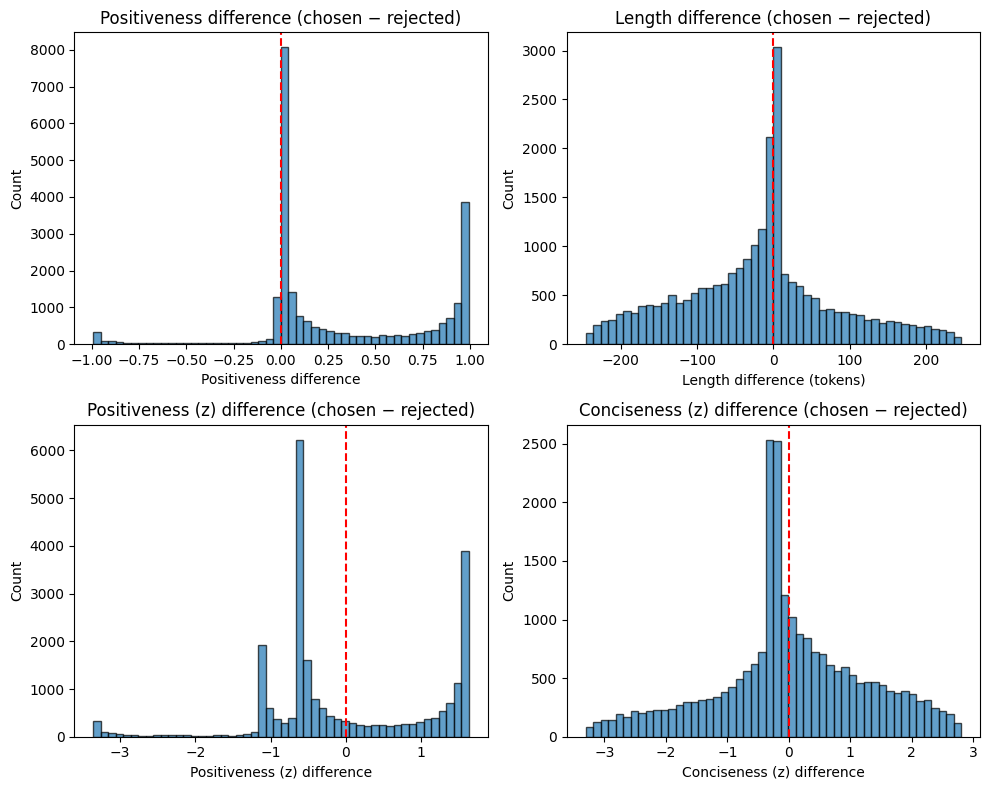

In [4]:
# Load preference dataset and score chosen/rejected with gold scorer
ALPHA = 1.0
DIVISOR = 250
SCORER_MAX_LEN = 512
BATCH_SIZE = 32
PREF_DATASET_ID = f"{USER_ID}/gpt2-imdb-preference-ALPHA{ALPHA}-len{MAX_NEW_TOKENS}-random"

import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
gold_tok = AutoTokenizer.from_pretrained("lvwerra/distilbert-imdb")
gold_rm = AutoModelForSequenceClassification.from_pretrained("lvwerra/distilbert-imdb").to(device)
gold_rm.eval()
pos_id = gold_rm.config.label2id["POSITIVE"]

def score_texts(texts, batch_size=BATCH_SIZE):
    pos_all, nlen_all = [], []
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            batch = texts[i : i + batch_size]
            enc = gold_tok(batch, padding=True, truncation=True, max_length=SCORER_MAX_LEN, return_tensors="pt").to(device)
            out = gold_rm(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"])
            probs = torch.softmax(out.logits, dim=-1)
            pos_all.extend(probs[:, pos_id].float().cpu().tolist())
            nlen_all.extend(torch.clamp(enc["attention_mask"].sum(dim=-1).float() / DIVISOR, 0.0, 1.0).cpu().tolist())
    return np.array(pos_all, dtype=np.float32), np.array(nlen_all, dtype=np.float32)

pref_ds = load_dataset(PREF_DATASET_ID, split="train")
chosen_texts = [ex["chosen"] for ex in pref_ds]
rejected_texts = [ex["rejected"] for ex in pref_ds]
pos_chosen, nlen_chosen = score_texts(chosen_texts)
pos_rejected, nlen_rejected = score_texts(rejected_texts)

# Score differences: chosen − rejected
pos_diff = pos_chosen - pos_rejected
len_diff = (nlen_chosen - nlen_rejected) * DIVISOR  # length diff in tokens
has_z = True  # we compute z from scored arrays
pos_z_chosen = (pos_chosen - pos_chosen.mean()) / (pos_chosen.std() + 1e-12)
pos_z_rejected = (pos_rejected - pos_rejected.mean()) / (pos_rejected.std() + 1e-12)
conc_chosen = 1.0 - nlen_chosen
conc_rejected = 1.0 - nlen_rejected
conc_z_chosen = (conc_chosen - conc_chosen.mean()) / (conc_chosen.std() + 1e-12)
conc_z_rejected = (conc_rejected - conc_rejected.mean()) / (conc_rejected.std() + 1e-12)
pos_z_diff = pos_z_chosen - pos_z_rejected
conc_z_diff = conc_z_chosen - conc_z_rejected

print("Preference dataset:", PREF_DATASET_ID)
print("Rows:", len(pref_ds))
print()
print("Score differences (chosen − rejected)")
print("  Positiveness:  mean=% .4f  std=%.4f  min=% .4f  max=% .4f" % (pos_diff.mean(), pos_diff.std(), pos_diff.min(), pos_diff.max()))
print("  Length:        mean=% .2f  std=%.2f  min=% .1f  max=% .1f" % (len_diff.mean(), len_diff.std(), len_diff.min(), len_diff.max()))
print("  Positiveness_z: mean=% .4f  std=%.4f  min=% .4f  max=% .4f" % (pos_z_diff.mean(), pos_z_diff.std(), pos_z_diff.min(), pos_z_diff.max()))
print("  Conciseness_z:  mean=% .4f  std=%.4f  min=% .4f  max=% .4f" % (conc_z_diff.mean(), conc_z_diff.std(), conc_z_diff.min(), conc_z_diff.max()))
print()

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()
axes[0].hist(pos_diff, bins=50, edgecolor="black", alpha=0.7)
axes[0].axvline(0, color="red", linestyle="--")
axes[0].set_xlabel("Positiveness difference")
axes[0].set_ylabel("Count")
axes[0].set_title("Positiveness difference (chosen − rejected)")
axes[1].hist(len_diff, bins=50, edgecolor="black", alpha=0.7)
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_xlabel("Length difference (tokens)")
axes[1].set_ylabel("Count")
axes[1].set_title("Length difference (chosen − rejected)")
axes[2].hist(pos_z_diff, bins=50, edgecolor="black", alpha=0.7)
axes[2].axvline(0, color="red", linestyle="--")
axes[2].set_xlabel("Positiveness (z) difference")
axes[2].set_ylabel("Count")
axes[2].set_title("Positiveness (z) difference (chosen − rejected)")
axes[3].hist(conc_z_diff, bins=50, edgecolor="black", alpha=0.7)
axes[3].axvline(0, color="red", linestyle="--")
axes[3].set_xlabel("Conciseness (z) difference")
axes[3].set_ylabel("Count")
axes[3].set_title("Conciseness (z) difference (chosen − rejected)")
plt.tight_layout()
plt.show()

## 3. Figure 2-style: Preference distributions (chosen vs rejected by group)

Load the **preference dataset** `{USER_ID}/gpt2-imdb-preference-ALPHA{ALPHA}-len{MAX_NEW_TOKENS}-random`, score chosen/rejected with the gold (DistilBERT) scorer and normalized_length, then plot KDEs of **sentiment** (positiveness) and **conciseness proxy** (normalized_length) for chosen vs rejected by group.

Preference dataset: mxcui/gpt2-imdb-preference-ALPHA1.0-len512-random


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loaded 24,720 rows. Minority: 4823 pairs, Majority: 19897 pairs


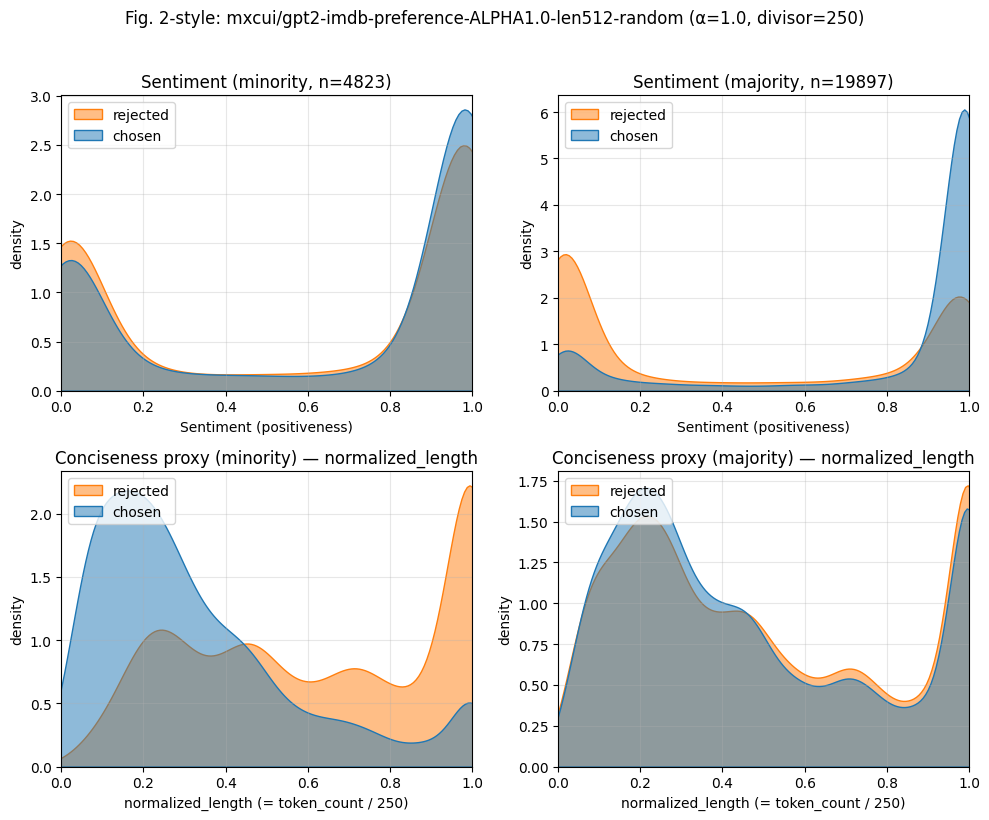

In [5]:
# Preference dataset and gold scorer for Fig. 2 and RM calibration
ALPHA = 1.0
DIVISOR = 250
SCORER_MAX_LEN = 512
BATCH_SIZE = 32
import torch
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification

PREF_DATASET_ID = f"{USER_ID}/gpt2-imdb-preference-ALPHA{ALPHA}-len{MAX_NEW_TOKENS}-random"
print("Preference dataset:", PREF_DATASET_ID)

# Gold scorer (DistilBERT) for positiveness; normalized_length from token count
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
GOLD_MODEL = "lvwerra/distilbert-imdb"
gold_tok = AutoTokenizer.from_pretrained(GOLD_MODEL)
gold_rm = AutoModelForSequenceClassification.from_pretrained(GOLD_MODEL).to(device)
gold_rm.eval()
pos_id = gold_rm.config.label2id["POSITIVE"]

def score_texts(texts, batch_size=BATCH_SIZE):
    pos_all, nlen_all = [], []
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            batch = texts[i : i + batch_size]
            enc = gold_tok(batch, padding=True, truncation=True, max_length=SCORER_MAX_LEN, return_tensors="pt").to(device)
            out = gold_rm(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"])
            probs = torch.softmax(out.logits, dim=-1)
            pos_all.extend(probs[:, pos_id].float().cpu().tolist())
            nlen_all.extend(torch.clamp(enc["attention_mask"].sum(dim=-1).float() / DIVISOR, 0.0, 1.0).cpu().tolist())
    return np.array(pos_all, dtype=np.float32), np.array(nlen_all, dtype=np.float32)

# Load preference dataset and build by_group (chosen / rejected per group_id)
pref_ds = load_dataset(PREF_DATASET_ID, split="train")
for col in ("chosen", "rejected", "group_id"):
    if col not in pref_ds.column_names:
        raise ValueError(f"Preference dataset must have column '{col}'")
by_group = {0: {"chosen": [], "rejected": []}, 1: {"chosen": [], "rejected": []}}
for ex in pref_ds:
    gid = int(ex["group_id"])
    if gid not in by_group:
        by_group[gid] = {"chosen": [], "rejected": []}
    by_group[gid]["chosen"].append(ex["chosen"])
    by_group[gid]["rejected"].append(ex["rejected"])
print(f"Loaded {len(pref_ds):,} rows. Minority: {len(by_group[0]['chosen'])} pairs, Majority: {len(by_group[1]['chosen'])} pairs")

# Score chosen and rejected per group → fig2 (for Fig. 2 plot and RM calibration)
fig2 = {}
for gid, gname in [(0, "minority"), (1, "majority")]:
    pos_c, nlen_c = score_texts(by_group[gid]["chosen"])
    pos_r, nlen_r = score_texts(by_group[gid]["rejected"])
    fig2[gname] = {"pos_chosen": pos_c, "pos_rejected": pos_r, "nlen_chosen": nlen_c, "nlen_rejected": nlen_r, "n": len(pos_c)}

# Figure 2-style: chosen vs rejected by group
import matplotlib.pyplot as plt
import seaborn as sns
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
C_CHOSEN, C_REJECTED = "C0", "C1"
ax = axes[0, 0]
sns.kdeplot(x=fig2["minority"]["pos_rejected"], ax=ax, color=C_REJECTED, label="rejected", fill=True, alpha=0.5)
sns.kdeplot(x=fig2["minority"]["pos_chosen"], ax=ax, color=C_CHOSEN, label="chosen", fill=True, alpha=0.5)
ax.set_xlim(0, 1); ax.set_ylim(0, None); ax.set_xlabel("Sentiment (positiveness)"); ax.set_ylabel("density")
ax.set_title(f"Sentiment (minority, n={fig2['minority']['n']})"); ax.legend(loc="upper left"); ax.grid(True, alpha=0.3)
ax = axes[0, 1]
sns.kdeplot(x=fig2["majority"]["pos_rejected"], ax=ax, color=C_REJECTED, label="rejected", fill=True, alpha=0.5)
sns.kdeplot(x=fig2["majority"]["pos_chosen"], ax=ax, color=C_CHOSEN, label="chosen", fill=True, alpha=0.5)
ax.set_xlim(0, 1); ax.set_ylim(0, None); ax.set_xlabel("Sentiment (positiveness)"); ax.set_ylabel("density")
ax.set_title(f"Sentiment (majority, n={fig2['majority']['n']})"); ax.legend(loc="upper left"); ax.grid(True, alpha=0.3)
ax = axes[1, 0]
sns.kdeplot(x=fig2["minority"]["nlen_rejected"], ax=ax, color=C_REJECTED, label="rejected", fill=True, alpha=0.5)
sns.kdeplot(x=fig2["minority"]["nlen_chosen"], ax=ax, color=C_CHOSEN, label="chosen", fill=True, alpha=0.5)
ax.set_xlim(0, 1); ax.set_ylim(0, None); ax.set_xlabel(f"normalized_length (= token_count / {DIVISOR})"); ax.set_ylabel("density")
ax.set_title("Conciseness proxy (minority) — normalized_length"); ax.legend(loc="upper left"); ax.grid(True, alpha=0.3)
ax = axes[1, 1]
sns.kdeplot(x=fig2["majority"]["nlen_rejected"], ax=ax, color=C_REJECTED, label="rejected", fill=True, alpha=0.5)
sns.kdeplot(x=fig2["majority"]["nlen_chosen"], ax=ax, color=C_CHOSEN, label="chosen", fill=True, alpha=0.5)
ax.set_xlim(0, 1); ax.set_ylim(0, None); ax.set_xlabel(f"normalized_length (= token_count / {DIVISOR})"); ax.set_ylabel("density")
ax.set_title("Conciseness proxy (majority) — normalized_length"); ax.legend(loc="upper left"); ax.grid(True, alpha=0.3)
fig.suptitle(f"Fig. 2-style: {PREF_DATASET_ID} (α={ALPHA}, divisor={DIVISOR})", y=1.02)
plt.tight_layout()
plt.show()

## RM calibration (len512)

Sample **chosen** responses only (one per prompt: the response with higher oracle score for that row’s group). Plot:

1. **Raw scores:** Oracle positiveness and conciseness (from gold scorer), majority/minority/vanilla RM predictions — for minority and majority samples.
2. **Normalized scores:** Oracle z-scores computed from the scored arrays; RM normalized from mean/std in `calibration/mxcui_gpt2-imdb-preference-ALPHA1.0-len512-random.json`.

In [6]:
# Use preference dataset: chosen texts and oracle scores from fig2 (section 3)
CALIB_SAMPLE = 2000
CALIB_SEED = 44

min_data = {
    "texts": by_group[0]["chosen"],
    "positiveness": fig2["minority"]["pos_chosen"],
    "conciseness": 1.0 - fig2["minority"]["nlen_chosen"],
}
maj_data = {
    "texts": by_group[1]["chosen"],
    "positiveness": fig2["majority"]["pos_chosen"],
    "conciseness": 1.0 - fig2["majority"]["nlen_chosen"],
}
# Oracle z-scores (preference dataset has no precomputed z; compute from scored arrays)
def zscore(x):
    x = np.asarray(x, dtype=np.float64)
    m, s = x.mean(), x.std()
    return (x - m) / s if s > 0 else np.zeros_like(x)
min_data["positiveness_z"] = zscore(min_data["positiveness"])
min_data["conciseness_z"] = zscore(min_data["conciseness"])
maj_data["positiveness_z"] = zscore(maj_data["positiveness"])
maj_data["conciseness_z"] = zscore(maj_data["conciseness"])

def cap_sample(data, n, seed=CALIB_SEED):
    if len(data["texts"]) <= n:
        return data
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(data["texts"]), size=n, replace=False)
    return {
        "texts": [data["texts"][i] for i in idx],
        "positiveness": data["positiveness"][idx],
        "conciseness": data["conciseness"][idx],
        "positiveness_z": data["positiveness_z"][idx],
        "conciseness_z": data["conciseness_z"][idx],
    }

min_data = cap_sample(min_data, CALIB_SAMPLE)
maj_data = cap_sample(maj_data, CALIB_SAMPLE)
print(f"Minority samples: {len(min_data['texts'])}, Majority samples: {len(maj_data['texts'])}")

Minority samples: 2000, Majority samples: 2000


In [7]:
import json
import os
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# Calibration JSON for len512 (reward_model_params: mean, std per model)
CALIB_LEN512 = os.path.join("calibration", "mxcui_gpt2-imdb-preference-ALPHA1.0-len512-random.json")
if not os.path.exists(CALIB_LEN512):
    CALIB_LEN512 = os.path.join("..", "calibration", "mxcui_gpt2-imdb-preference-ALPHA1.0-len512-random.json")
with open(CALIB_LEN512) as f:
    calib = json.load(f)

# Hub IDs from calibration (preference_dataset points to len512)
rp = calib["reward_model_params"]
# Infer model IDs (keys are full hub IDs)
VANILLA_ID = "mxcui/vanilla-imdb-reward-ALPHA1.0-len512-gpt2"
RM_MIN_ID = "mxcui/maxmin-imdb-reward-ALPHA1.0-len512-minority-gpt2"
RM_MAJ_ID = "mxcui/maxmin-imdb-reward-ALPHA1.0-len512-majority-gpt2"
RM_MAX_LEN = 256
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 32

print("Loading RMs:", VANILLA_ID, RM_MIN_ID, RM_MAJ_ID)
rm_vanilla = AutoModelForSequenceClassification.from_pretrained(VANILLA_ID).to(device)
rm_min = AutoModelForSequenceClassification.from_pretrained(RM_MIN_ID).to(device)
rm_maj = AutoModelForSequenceClassification.from_pretrained(RM_MAJ_ID).to(device)
rm_vanilla.eval()
rm_min.eval()
rm_maj.eval()
tok = AutoTokenizer.from_pretrained(RM_MAJ_ID)
if tok.pad_token is None:
    tok.pad_token = tok.eos_token

Loading RMs: mxcui/vanilla-imdb-reward-ALPHA1.0-len512-gpt2 mxcui/maxmin-imdb-reward-ALPHA1.0-len512-minority-gpt2 mxcui/maxmin-imdb-reward-ALPHA1.0-len512-majority-gpt2


Loading weights:   0%|          | 0/149 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/149 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/149 [00:00<?, ?it/s]

In [8]:
def rm_logits(texts, model, batch_size=BATCH_SIZE):
    out = []
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            batch = texts[i : i + batch_size]
            enc = tok(batch, padding=True, truncation=True, max_length=RM_MAX_LEN, return_tensors="pt").to(device)
            logit = model(**enc).logits.squeeze(-1)
            out.extend(logit.float().cpu().tolist())
    return np.array(out, dtype=np.float32)

# Score minority and majority texts with all three RMs
min_vanilla = rm_logits(min_data["texts"], rm_vanilla)
min_rm_min  = rm_logits(min_data["texts"], rm_min)
min_rm_maj  = rm_logits(min_data["texts"], rm_maj)
maj_vanilla = rm_logits(maj_data["texts"], rm_vanilla)
maj_rm_min  = rm_logits(maj_data["texts"], rm_min)
maj_rm_maj  = rm_logits(maj_data["texts"], rm_maj)

# Normalize RM scores using mean/std from calibration JSON
def normalize_rm(scores, hub_id):
    params = calib["reward_model_params"].get(hub_id, {})
    m, s = params.get("mean", 0.0), params.get("std", 1.0)
    return (scores - m) / s if s else scores

min_vanilla_n = normalize_rm(min_vanilla, VANILLA_ID)
min_rm_min_n  = normalize_rm(min_rm_min, RM_MIN_ID)
min_rm_maj_n  = normalize_rm(min_rm_maj, RM_MAJ_ID)
maj_vanilla_n = normalize_rm(maj_vanilla, VANILLA_ID)
maj_rm_min_n  = normalize_rm(maj_rm_min, RM_MIN_ID)
maj_rm_maj_n  = normalize_rm(maj_rm_maj, RM_MAJ_ID)

print("Raw RM stats (minority texts): vanilla mean=%.4f, minority RM mean=%.4f, majority RM mean=%.4f" % (min_vanilla.mean(), min_rm_min.mean(), min_rm_maj.mean()))
print("Raw RM stats (majority texts): vanilla mean=%.4f, minority RM mean=%.4f, majority RM mean=%.4f" % (maj_vanilla.mean(), maj_rm_min.mean(), maj_rm_maj.mean()))

Raw RM stats (minority texts): vanilla mean=0.5621, minority RM mean=1.4313, majority RM mean=0.1823
Raw RM stats (majority texts): vanilla mean=0.6678, minority RM mean=0.7309, majority RM mean=0.4267


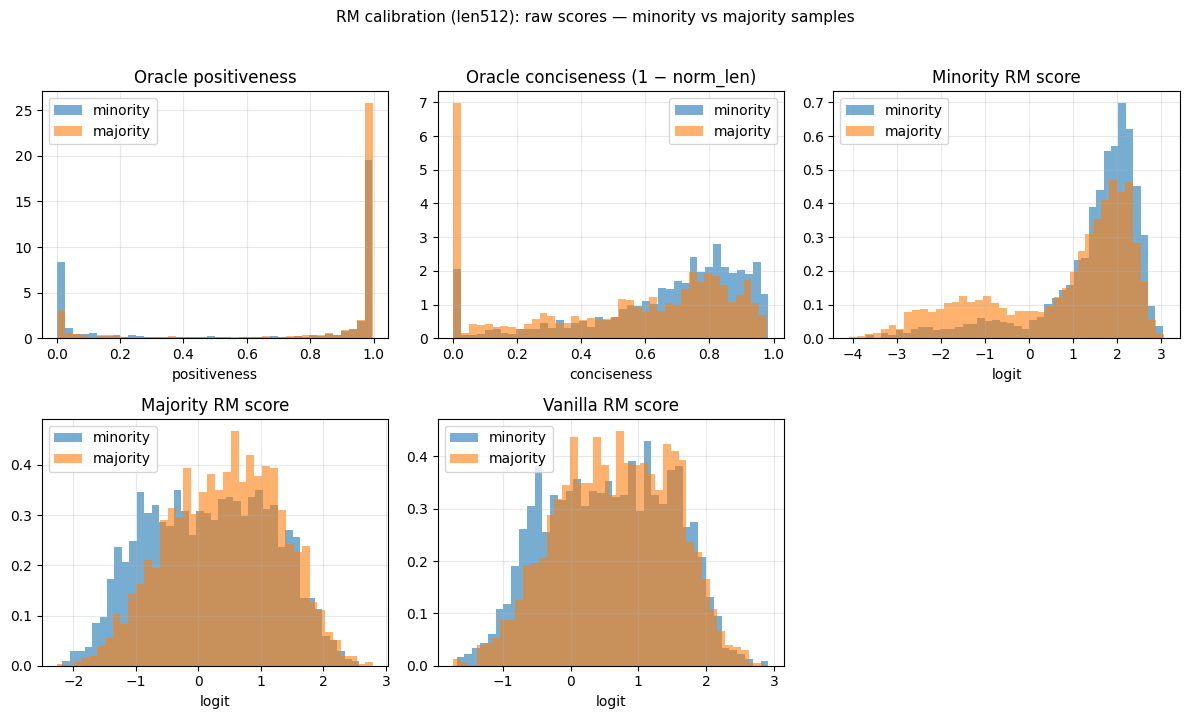

In [9]:
import matplotlib.pyplot as plt

# Raw scores: oracle positiveness, oracle conciseness, minority RM, majority RM, vanilla
C_MIN, C_MAJ = "tab:blue", "tab:orange"
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
axes = axes.flatten()

def plot_pair(ax, min_vals, maj_vals, title, xlabel):
    ax.hist(min_vals, bins=40, density=True, alpha=0.6, color=C_MIN, label="minority")
    ax.hist(maj_vals, bins=40, density=True, alpha=0.6, color=C_MAJ, label="majority")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.legend()
    ax.grid(True, alpha=0.3)

plot_pair(axes[0], min_data["positiveness"], maj_data["positiveness"], "Oracle positiveness", "positiveness")
plot_pair(axes[1], min_data["conciseness"], maj_data["conciseness"], "Oracle conciseness (1 − norm_len)", "conciseness")
plot_pair(axes[2], min_rm_min, maj_rm_min, "Minority RM score", "logit")
plot_pair(axes[3], min_rm_maj, maj_rm_maj, "Majority RM score", "logit")
plot_pair(axes[4], min_vanilla, maj_vanilla, "Vanilla RM score", "logit")
axes[5].axis("off")
fig.suptitle("RM calibration (len512): raw scores — minority vs majority samples", fontsize=11, y=1.02)
plt.tight_layout()
plt.show()

Vanilla RM vs Oracle (chosen, n=4000):
  Pearson(vanilla_rm, positiveness): r = 0.6520, p = 0.00e+00
  Pearson(vanilla_rm, length):       r = -0.2533, p = 0.00e+00



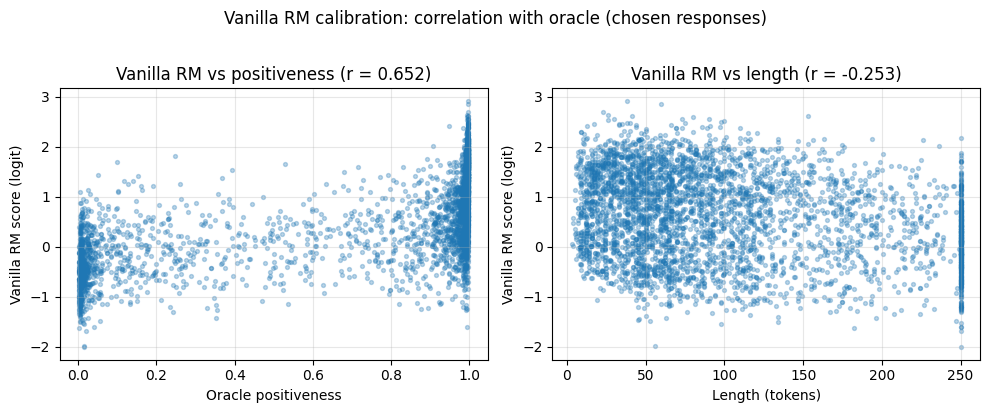

In [10]:
# Vanilla RM score vs Oracle: scatter plots and Pearson (chosen responses, pooled)
# Use chosen responses to see if vanilla RM correlates with positiveness and length
DIVISOR_CALIB = 250  # same as DIVISOR from section 3
n_calib = min(2000, len(by_group[0]["chosen"]), len(by_group[1]["chosen"]))
rng = np.random.default_rng(CALIB_SEED)

def sample_chosen(group_id, n):
    idx = rng.choice(len(by_group[group_id]["chosen"]), size=n, replace=False)
    texts = [by_group[group_id]["chosen"][i] for i in idx]
    pos = fig2["minority" if group_id == 0 else "majority"]["pos_chosen"][idx]
    nlen = fig2["minority" if group_id == 0 else "majority"]["nlen_chosen"][idx]
    return texts, np.array(pos, dtype=np.float32), np.array(nlen, dtype=np.float32)

t0, p0, n0 = sample_chosen(0, n_calib)
t1, p1, n1 = sample_chosen(1, n_calib)
all_texts = t0 + t1
pos_all = np.concatenate([p0, p1])
nlen_all = np.concatenate([n0, n1])
length_all = nlen_all * DIVISOR_CALIB  # length in tokens
vanilla_all = rm_logits(all_texts, rm_vanilla)

r_pos, p_pos = stats.pearsonr(vanilla_all, pos_all)
r_len, p_len = stats.pearsonr(vanilla_all, length_all)
print("Vanilla RM vs Oracle (chosen, n=%d):" % len(vanilla_all))
print("  Pearson(vanilla_rm, positiveness): r = %.4f, p = %.2e" % (r_pos, p_pos))
print("  Pearson(vanilla_rm, length):       r = %.4f, p = %.2e" % (r_len, p_len))
print()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(pos_all, vanilla_all, alpha=0.3, s=8)
axes[0].set_xlabel("Oracle positiveness")
axes[0].set_ylabel("Vanilla RM score (logit)")
axes[0].set_title("Vanilla RM vs positiveness (r = %.3f)" % r_pos)
axes[0].grid(True, alpha=0.3)
axes[1].scatter(length_all, vanilla_all, alpha=0.3, s=8)
axes[1].set_xlabel("Length (tokens)")
axes[1].set_ylabel("Vanilla RM score (logit)")
axes[1].set_title("Vanilla RM vs length (r = %.3f)" % r_len)
axes[1].grid(True, alpha=0.3)
fig.suptitle("Vanilla RM calibration: correlation with oracle (chosen responses)", y=1.02)
plt.tight_layout()
plt.show()

### PPO parameters that could bias toward conciseness (independent of RM)

Given that Vanilla RM correlates weakly with length (r≈−0.25) but strongly with positiveness (r≈0.65), conciseness may come from **PPO training dynamics** rather than the RM. Key params from `unified_ppo_training.py`:

| Parameter | Value | Effect on length |
|-----------|-------|------------------|
| **`kl_coef`** | 0.1 | KL is summed over the sequence → longer responses accumulate more KL penalty. Total reward = score − 0.1×KL, so longer outputs get a stronger negative term. **Implicit pressure toward shorter responses.** |
| **`stop_token`** | `"eos"` | Generation stops at EOS. Policy can learn to emit EOS early to end the response and avoid further KL accumulation. |
| **`missing_eos_penalty`** | 0.0 | (Was 1.0; removed to prevent early-EOS collapse.) No explicit penalty for lacking EOS, but early EOS still truncates length. |
| **`per_device_train_batch_size`** | 32 | Number of prompts per batch (not response length). |
| **TRL internal `batch_size`** | (check TRL PPOConfig) | In some TRL IMDB examples, `batch_size` in PPOConfig controls **response length in tokens**. If small (e.g. 16), generations are capped short. |

**Conclusion:** The KL penalty (`kl_coef × Σ KL per token`) creates an inherent pressure: each extra token adds to the KL sum and reduces total reward. Shorter responses thus receive a smaller KL penalty and can achieve higher net reward even with similar RM scores. This could explain vanilla PPO producing concise responses even when the RM’s length correlation is modest.

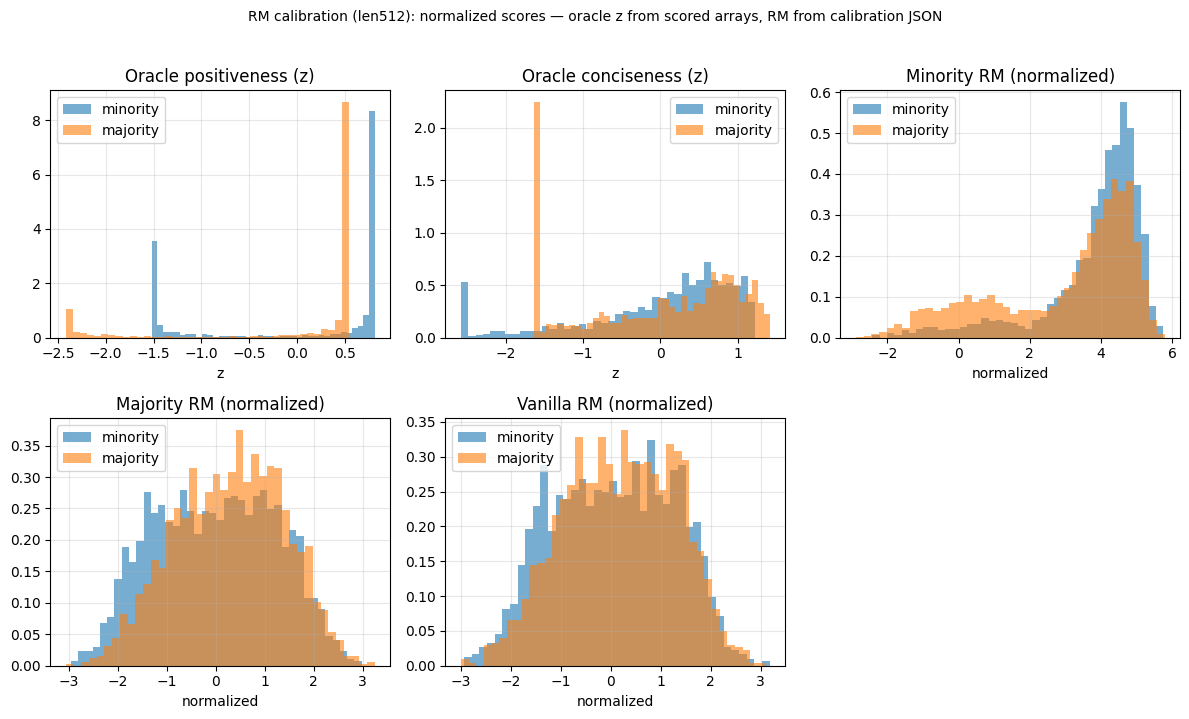

In [11]:
# Normalized scores: oracle z (computed from scored arrays), RM normalized from calibration JSON
fig2_plot, axes2 = plt.subplots(2, 3, figsize=(12, 7))
axes2 = axes2.flatten()
plot_pair(axes2[0], min_data["positiveness_z"], maj_data["positiveness_z"], "Oracle positiveness (z)", "z")
plot_pair(axes2[1], min_data["conciseness_z"], maj_data["conciseness_z"], "Oracle conciseness (z)", "z")
plot_pair(axes2[2], min_rm_min_n, maj_rm_min_n, "Minority RM (normalized)", "normalized")
plot_pair(axes2[3], min_rm_maj_n, maj_rm_maj_n, "Majority RM (normalized)", "normalized")
plot_pair(axes2[4], min_vanilla_n, maj_vanilla_n, "Vanilla RM (normalized)", "normalized")
axes2[5].axis("off")
fig2_plot.suptitle("RM calibration (len512): normalized scores — oracle z from scored arrays, RM from calibration JSON", fontsize=10, y=1.02)
plt.tight_layout()
plt.show()

## 4. Conciseness and positiveness: vanilla vs maxmin PPO policies

Load evaluation datasets for **vanilla** and **maxmin** PPO policies (generated by `evaluate_ppo_policy.sh`). If they include positiveness and length/conciseness scores, compare mean **positiveness** and **conciseness** (normalized length) between the two policies. If only `prompt` and `completion` exist, score them in-notebook with the same sentiment model and length divisor as above.

Conciseness and positiveness: vanilla vs maxmin PPO policies
 method     n  mean_positiveness  std_positiveness  mean_conciseness  std_conciseness
vanilla 24872           0.954448          0.142288          0.358823         0.377516
 maxmin 24872           0.885769          0.225022          0.657650         0.287643



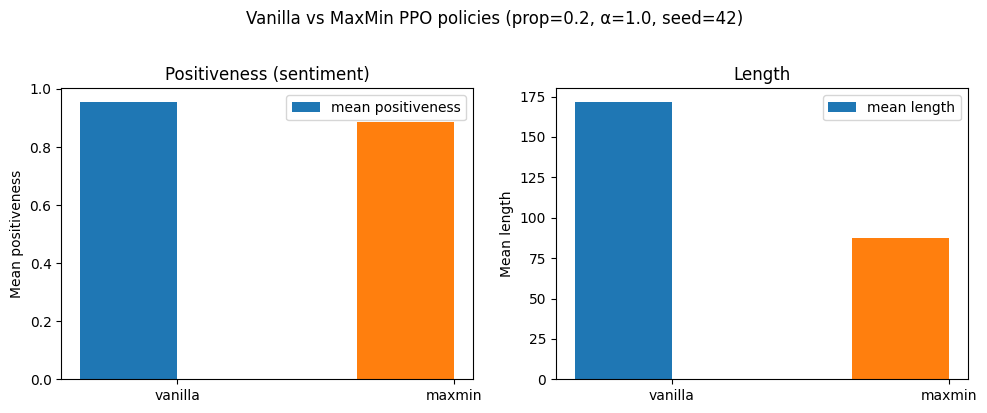

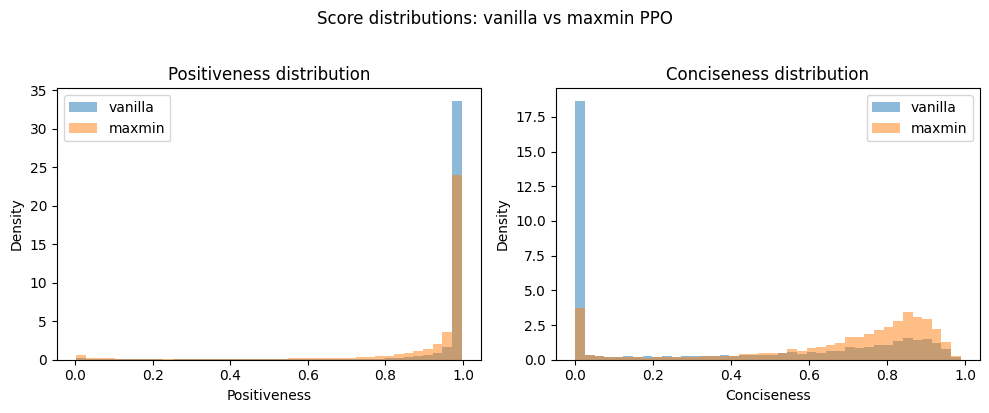

In [21]:
from datasets import load_dataset
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
# PPO eval dataset naming (match evaluate_ppo_policy.sh)
USER_ID = "mxcui"
PPO_SEED = 42
PPO_PROPORTION = 0.2
PPO_ALPHA = 1.0
DIVISOR_PPO = 250  # same as DIVISOR for normalized_length -> conciseness = 1 - normalized_length

def _ppo_eval_id(method):
    return f"{USER_ID}/{method}-imdb-ppo-eval-prop{PPO_PROPORTION}-alpha{PPO_ALPHA}-seed{PPO_SEED}-kl0.1-gpt2"

results = {}
for method in ["vanilla", "maxmin"]:
    try:
        data = load_dataset(_ppo_eval_id(method))
        split = list(data.keys())[0] if hasattr(data, "keys") else "train"
        ds_ppo = data[split] if hasattr(data, "keys") else data
        df_ppo = ds_ppo.to_pandas()
    except Exception as e:
        print(f"Could not load {method} PPO eval dataset: {e}")
        print("  Run: ./scripts/evaluate_ppo_policy.sh (generate + score) to create them.")
        continue

    # Score if needed (only prompt + completion)
    if "positiveness" not in df_ppo.columns or "length" not in df_ppo.columns:
        import torch
        from transformers import AutoTokenizer, AutoModelForSequenceClassification
        model_name = "lvwerra/distilbert-imdb"
        tokenizer = AutoTokenizer.from_pretrained(model_name)
        model = AutoModelForSequenceClassification.from_pretrained(model_name)
        model.eval()
        pos_id = model.config.label2id["POSITIVE"]
        positiveness_list = []
        length_list = []
        batch_size = 64
        texts = df_ppo["completion"].astype(str).tolist()
        for i in range(0, len(texts), batch_size):
            batch = texts[i : i + batch_size]
            enc = tokenizer(batch, padding=True, truncation=True, max_length=512, return_tensors="pt")
            with torch.no_grad():
                out = model(**enc)
            probs = torch.softmax(out.logits, dim=-1)
            positiveness_list.extend(probs[:, pos_id].tolist())
            length_list.extend(enc["attention_mask"].sum(dim=1).tolist())
        df_ppo["positiveness"] = positiveness_list
        df_ppo["length"] = length_list

    df_ppo["normalized_length"] = np.clip(df_ppo["length"].astype(float) / DIVISOR_PPO, 0, 1)
    df_ppo["conciseness"] = 1 - df_ppo["normalized_length"]
    results[method] = df_ppo

if not results:
    print("No PPO eval data loaded. Skipping analysis.")
else:
    # Summary table
    print("Conciseness and positiveness: vanilla vs maxmin PPO policies")
    print("=" * 70)
    rows = []
    for method, d in results.items():
        rows.append({
            "method": method,
            "n": len(d),
            "mean_positiveness": d["positiveness"].mean(),
            "std_positiveness": d["positiveness"].std(),
            "mean_conciseness": d["conciseness"].mean(),
            "std_conciseness": d["conciseness"].std(),
        })
    summary = pd.DataFrame(rows)
    print(summary.to_string(index=False))
    print()

    # Bar plot: mean positiveness and mean conciseness
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    x = np.arange(len(results))
    width = 0.35
    methods = list(results.keys())
    axes[0].bar(x - width/2, [results[m]["positiveness"].mean() for m in methods], width, label="mean positiveness", color=["C0", "C1"])
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(methods)
    axes[0].set_ylabel("Mean positiveness")
    axes[0].set_title("Positiveness (sentiment)")
    axes[0].legend()

    axes[1].bar(x - width/2, [results[m]["length"].mean() for m in methods], width, label="mean length", color=["C0", "C1"])
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(methods)
    axes[1].set_ylabel("Mean length")
    axes[1].set_title("Length")
    axes[1].legend()
    fig.suptitle(f"Vanilla vs MaxMin PPO policies (prop={PPO_PROPORTION}, α={PPO_ALPHA}, seed={PPO_SEED})", y=1.02)
    plt.tight_layout()
    plt.show()

    # Optional: KDE of positiveness and conciseness per policy
    fig2, axes2 = plt.subplots(1, 2, figsize=(10, 4))
    for method, d in results.items():
        axes2[0].hist(d["positiveness"], bins=40, alpha=0.5, label=method, density=True)
        axes2[1].hist(d["conciseness"], bins=40, alpha=0.5, label=method, density=True)
    axes2[0].set_xlabel("Positiveness")
    axes2[0].set_ylabel("Density")
    axes2[0].set_title("Positiveness distribution")
    axes2[0].legend()
    axes2[1].set_xlabel("Conciseness")
    axes2[1].set_ylabel("Density")
    axes2[1].set_title("Conciseness distribution")
    axes2[1].legend()
    fig2.suptitle("Score distributions: vanilla vs maxmin PPO", y=1.02)
    plt.tight_layout()
    plt.show()

### 4.1 Batch minority/majority mean score and worst-group selection frequency (MaxMin PPO)

For a **maxmin** PPO run, training logs to WandB the batch mean reward per group and which group was selected as worst each step. Below we fetch a run's history and plot:
1. **Batch minority and majority mean score** over training steps.
2. **Frequency** that each group (minority vs majority) was selected as the worst group.

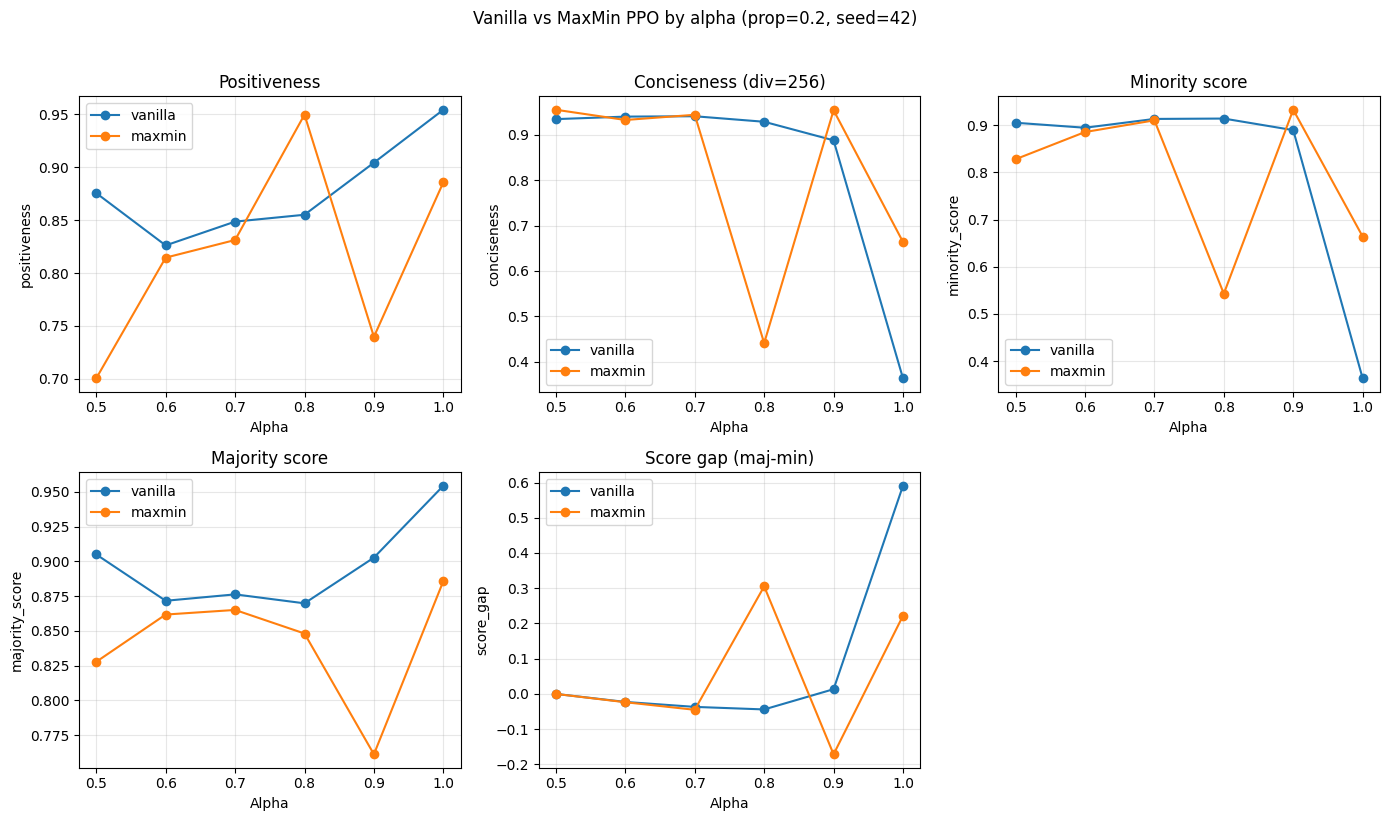

In [2]:
from datasets import load_dataset
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

USER_ID = "mxcui"
PPO_SEED = 42
PPO_PROPORTION = 0.2
DIVISOR = 256  # normalized_length = length / DIVISOR, conciseness = 1 - normalized_length

def _ppo_eval_id(method, alpha):
    return f"{USER_ID}/{method}-imdb-ppo-eval-prop{PPO_PROPORTION}-alpha{alpha}-seed{PPO_SEED}-kl0.1-gpt2"

def oracle_minority(pos, nl, alpha):
    return (1 - nl) * alpha + (1 - alpha) * pos

def oracle_majority(pos, nl, alpha):
    return (1 - nl) * (1 - alpha) + alpha * pos

ALPHAS = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
results = {}

for alpha in ALPHAS:
    for method in ["vanilla", "maxmin"]:
        try:
            data = load_dataset(_ppo_eval_id(method, alpha))
            split = list(data.keys())[0] if hasattr(data, "keys") else "train"
            df_ppo = data[split].to_pandas() if hasattr(data, "keys") else data.to_pandas()
        except Exception as e:
            print(f"Could not load {method} alpha={alpha}: {e}")
            continue
        if "positiveness" not in df_ppo.columns or "length" not in df_ppo.columns:
            import torch
            from transformers import AutoTokenizer, AutoModelForSequenceClassification
            tokenizer = AutoTokenizer.from_pretrained("lvwerra/distilbert-imdb")
            model = AutoModelForSequenceClassification.from_pretrained("lvwerra/distilbert-imdb")
            model.eval()
            pos_id = model.config.label2id["POSITIVE"]
            pl, ll = [], []
            texts = df_ppo["completion"].astype(str).tolist()
            for i in range(0, len(texts), 64):
                enc = tokenizer(texts[i:i+64], padding=True, truncation=True, max_length=512, return_tensors="pt")
                with torch.no_grad():
                    probs = torch.softmax(model(**enc).logits, dim=-1)
                pl.extend(probs[:, pos_id].tolist())
                ll.extend(enc["attention_mask"].sum(dim=1).tolist())
            df_ppo["positiveness"], df_ppo["length"] = pl, ll
        df_ppo["normalized_length"] = np.clip(df_ppo["length"].astype(float) / DIVISOR, 0, 1)
        df_ppo["conciseness"] = 1 - df_ppo["normalized_length"]
        df_ppo["minority_score"] = oracle_minority(df_ppo["positiveness"], df_ppo["normalized_length"], alpha)
        df_ppo["majority_score"] = oracle_majority(df_ppo["positiveness"], df_ppo["normalized_length"], alpha)
        df_ppo["score_gap"] = df_ppo["majority_score"] - df_ppo["minority_score"]
        results[(alpha, method)] = df_ppo

if not results:
    print("No PPO eval data loaded.")
else:
    rows = [{"alpha": a, "method": m,
             "positiveness": d["positiveness"].mean(),
             "conciseness": d["conciseness"].mean(),
             "minority_score": d["minority_score"].mean(),
             "majority_score": d["majority_score"].mean(),
             "score_gap": d["score_gap"].mean()}
            for (a, m), d in results.items()]
    df_agg = pd.DataFrame(rows)

    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    axes = axes.flatten()
    for ax, metric, title in zip(axes,
        ["positiveness", "conciseness", "minority_score", "majority_score", "score_gap"],
        ["Positiveness", "Conciseness (div=256)", "Minority score", "Majority score", "Score gap (maj-min)"]):
        for method in ["vanilla", "maxmin"]:
            sub = df_agg[df_agg["method"] == method].sort_values("alpha")
            if len(sub): ax.plot(sub["alpha"], sub[metric], "o-", label=method)
        ax.set_xlabel("Alpha"); ax.set_ylabel(metric); ax.set_title(title)
        ax.legend(); ax.grid(True, alpha=0.3)
    axes[5].set_visible(False)
    fig.suptitle(f"Vanilla vs MaxMin PPO by alpha (prop={PPO_PROPORTION}, seed={PPO_SEED})", y=1.02)
    plt.tight_layout(); plt.show()

